In [ ]:
# Install missing packages if required.
# Uncomment and run this cell in a fresh environment.

# %pip install -q librosa soundfile scikit-learn xgboost seaborn pandas matplotlib numpy tqdm kagglehub


In [ ]:
import os
import glob
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import soundfile as sf

from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Libraries loaded.")


Libraries loaded.


In [ ]:
# KaggleHub download
import kagglehub

DATASET_PATH = kagglehub.dataset_download(
    "kambingbersayaphitam/speech-dataset-of-human-and-ai-generated-voices"
)

print("Dataset path:", DATASET_PATH)


100%|██████████| 1.36G/1.36G [00:20<00:00, 69.7MB/s]

Extracting files...


Dataset path: /root/.cache/kagglehub/datasets/kambingbersayaphitam/speech-dataset-of-human-and-ai-generated-voices/versions/1


In [ ]:
# Inspect dataset files and folders
root = Path(DATASET_PATH)

all_files = [p for p in root.rglob("*") if p.is_file()]
print(f"Total files: {len(all_files)}")

for p in all_files[:100]:
    print(p.relative_to(root))


Total files: 43
Dataset.csv
Real/Real/Recording (8).wav
Real/Real/Recording (12).wav
Real/Real/Recording (13).wav
Real/Real/Recording (17).wav
Real/Real/Recording (6).wav
Real/Real/Recording (20).wav
Real/Real/Recording (4).wav
Real/Real/Recording (19).wav
Real/Real/Recording (11).wav
Real/Real/Recording (10).wav
Real/Real/Recording (15).wav
Real/Real/Recording (9).wav
Real/Real/Recording (21).wav
Real/Real/Recording (1).wav
Real/Real/Recording (18).wav
Real/Real/Recording (14).wav
Real/Real/Recording (5).wav
Real/Real/Recording (3).wav
Real/Real/Recording (2).wav
Real/Real/Recording (16).wav
Real/Real/Recording (7).wav
Fake/Fake/Recording (8).wav
Fake/Fake/Recording (12).wav
Fake/Fake/Recording (13).wav
Fake/Fake/Recording (17).wav
Fake/Fake/Recording (6).wav
Fake/Fake/Recording (20).wav
Fake/Fake/Recording (4).wav
Fake/Fake/Recording (19).wav
Fake/Fake/Recording (11).wav
Fake/Fake/Recording (10).wav
Fake/Fake/Recording (15).wav
Fake/Fake/Recording (9).wav
Fake/Fake/Recording (21).wav

In [ ]:
AUDIO_EXTENSIONS = {".wav", ".mp3", ".flac", ".ogg", ".m4a", ".aac"}

audio_files = [p for p in all_files if p.suffix.lower() in AUDIO_EXTENSIONS]
print("Audio files found:", len(audio_files))

def infer_label(path, root):
    # First try immediate parent directory.
    parent = path.parent.name.strip()
    if parent and parent != root.name:
        return parent

    # Otherwise inspect path components for common labels.
    parts = [x.lower() for x in path.parts]
    for label in ["real", "fake", "human", "ai", "generated", "synthetic"]:
        if label in parts:
            return label

    return None

records = []
for p in audio_files:
    records.append({
        "path": str(p),
        "label_raw": infer_label(p, root)
    })

df_files = pd.DataFrame(records)

print(df_files.head())
print("\nLabel counts:")
print(df_files["label_raw"].value_counts(dropna=False))

if df_files["label_raw"].isna().all():
    print("\nWARNING: Labels could not be inferred from directory names.")
    print("Inspect the dataset structure and connect its metadata/CSV here.")


Audio files found: 42
                                                path label_raw
0  /root/.cache/kagglehub/datasets/kambingbersaya...      Real
1  /root/.cache/kagglehub/datasets/kambingbersaya...      Real
2  /root/.cache/kagglehub/datasets/kambingbersaya...      Real
3  /root/.cache/kagglehub/datasets/kambingbersaya...      Real
4  /root/.cache/kagglehub/datasets/kambingbersaya...      Real

Label counts:
label_raw
Real    21
Fake    21
Name: count, dtype: int64


In [ ]:
# Remove files whose labels could not be inferred.
df_files = df_files.dropna(subset=["label_raw"]).copy()

# Normalize common labels while preserving other class names.
def normalize_label(x):
    x = str(x).strip().lower()
    mapping = {
        "human": "real",
        "real": "real",
        "natural": "real",
        "ai": "fake",
        "fake": "fake",
        "generated": "fake",
        "synthetic": "fake",
    }
    return mapping.get(x, x)

df_files["label"] = df_files["label_raw"].map(normalize_label)

print("Classes:", sorted(df_files["label"].unique()))
print(df_files["label"].value_counts())

if df_files["label"].nunique() < 2:
    raise ValueError(
        "At least two classes are required. Check the dataset labels/metadata."
    )


Classes: ['fake', 'real']
label
real    21
fake    21
Name: count, dtype: int64


In [ ]:
train_df, test_df = train_test_split(
    df_files,
    test_size=0.20,
    stratify=df_files["label"],
    random_state=RANDOM_STATE
)

print("Train:", len(train_df))
print("Test :", len(test_df))
print("\nTrain distribution:")
print(train_df["label"].value_counts(normalize=True))
print("\nTest distribution:")
print(test_df["label"].value_counts(normalize=True))


Train: 33
Test : 9

Train distribution:
label
real    0.515152
fake    0.484848
Name: proportion, dtype: float64

Test distribution:
label
fake    0.555556
real    0.444444
Name: proportion, dtype: float64


In [ ]:
# Feature extraction configuration
SR = 16000
DURATION = 5.0
N_SAMPLES = int(SR * DURATION)

N_MFCC = 13
N_MELS = 40
N_FFT = 1024
HOP_LENGTH = 512

def load_audio(path, sr=SR, duration=DURATION):
    y, _ = librosa.load(path, sr=sr, mono=True)

    target_len = int(sr * duration)
    if len(y) < target_len:
        y = np.pad(y, (0, target_len - len(y)))
    else:
        y = y[:target_len]

    # Peak normalization
    peak = np.max(np.abs(y))
    if peak > 0:
        y = y / peak

    return y

def stats(mat):
    return np.concatenate([np.mean(mat, axis=1), np.std(mat, axis=1)])

def extract_features(path, representation):
    y = load_audio(path)

    mfcc = librosa.feature.mfcc(
        y=y, sr=SR, n_mfcc=N_MFCC,
        n_fft=N_FFT, hop_length=HOP_LENGTH
    )

    mel = librosa.feature.melspectrogram(
        y=y, sr=SR, n_mels=N_MELS,
        n_fft=N_FFT, hop_length=HOP_LENGTH
    )
    mel_db = librosa.power_to_db(mel, ref=np.max)

    spectral = np.vstack([
        librosa.feature.spectral_centroid(y=y, sr=SR, n_fft=N_FFT, hop_length=HOP_LENGTH),
        librosa.feature.spectral_bandwidth(y=y, sr=SR, n_fft=N_FFT, hop_length=HOP_LENGTH),
        librosa.feature.spectral_rolloff(y=y, sr=SR, n_fft=N_FFT, hop_length=HOP_LENGTH),
        librosa.feature.zero_crossing_rate(y, hop_length=HOP_LENGTH)
    ])

    if representation == "MFCC":
        return stats(mfcc)
    elif representation == "Mel":
        return stats(mel_db)
    elif representation == "MFCC + Spectral":
        return np.concatenate([stats(mfcc), stats(spectral)])
    elif representation == "MFCC + Mel":
        return np.concatenate([stats(mfcc), stats(mel_db)])
    else:
        raise ValueError(f"Unknown representation: {representation}")


In [ ]:
REPRESENTATIONS = [
    "MFCC",
    "Mel",
    "MFCC + Spectral",
    "MFCC + Mel"
]

def build_feature_matrix(dataframe, representation):
    X, y, paths = [], [], []

    for row in tqdm(
        dataframe.itertuples(index=False),
        total=len(dataframe),
        desc=f"Extracting {representation}"
    ):
        try:
            feat = extract_features(row.path, representation)
            X.append(feat)
            y.append(row.label)
            paths.append(row.path)
        except Exception as e:
            print(f"Skipping {row.path}: {e}")

    return np.asarray(X, dtype=np.float32), np.asarray(y), paths

feature_sets = {}

for rep in REPRESENTATIONS:
    X_train, y_train, train_paths = build_feature_matrix(train_df, rep)
    X_test, y_test, test_paths = build_feature_matrix(test_df, rep)

    feature_sets[rep] = {
        "X_train": X_train,
        "y_train": y_train,
        "X_test": X_test,
        "y_test": y_test,
        "train_paths": train_paths,
        "test_paths": test_paths
    }

    print(
        f"{rep}: train={X_train.shape}, test={X_test.shape}"
    )


Extracting MFCC:   0%|          | 0/33 [00:00<?, ?it/s]

Extracting MFCC:   0%|          | 0/9 [00:00<?, ?it/s]

MFCC: train=(33, 26), test=(9, 26)


Extracting Mel:   0%|          | 0/33 [00:00<?, ?it/s]

Extracting Mel:   0%|          | 0/9 [00:00<?, ?it/s]

Mel: train=(33, 80), test=(9, 80)


... (2 outputs left out)

MFCC + Spectral: train=(33, 34), test=(9, 34)


Extracting MFCC + Mel:   0%|          | 0/33 [00:00<?, ?it/s]

Extracting MFCC + Mel:   0%|          | 0/9 [00:00<?, ?it/s]

MFCC + Mel: train=(33, 106), test=(9, 106)


In [ ]:
feature_dimensions = pd.DataFrame({
    rep: {
        "Number of features": feature_sets[rep]["X_train"].shape[1]
    }
    for rep in REPRESENTATIONS
}).T

display(feature_dimensions)


,Number of features
MFCC,26
Mel,80
MFCC + Spectral,34
MFCC + Mel,106


In [ ]:
models = {
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(
            kernel="rbf",
            C=10,
            gamma="scale",
            probability=True,
            random_state=RANDOM_STATE
        ))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        class_weight="balanced"
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "MLP": Pipeline([
        ("scaler", StandardScaler()),
        ("model", MLPClassifier(
            hidden_layer_sizes=(128, 64),
            activation="relu",
            early_stopping=True,
            validation_fraction=0.15,
            max_iter=100,
            random_state=RANDOM_STATE
        ))
    ])
}


In [ ]:
def evaluate_model(model, X_train, y_train, X_test, y_test):
    # Use LabelEncoder to convert string labels ('fake', 'real') to integers (0, 1)
    le = LabelEncoder()
    y_train_encoded = le.fit_transform(y_train)
    y_test_encoded = le.transform(y_test)

    start = time.perf_counter()
    model.fit(X_train, y_train_encoded)
    train_time = time.perf_counter() - start

    start = time.perf_counter()
    pred_encoded = model.predict(X_test)
    inference_time = time.perf_counter() - start

    # Inverse transform predictions back to original string labels
    pred = le.inverse_transform(pred_encoded)

    result = {
        "Accuracy": accuracy_score(y_test_encoded, pred_encoded),
        "Precision": precision_score(y_test_encoded, pred_encoded, average="weighted", zero_division=0),
        "Recall": recall_score(y_test_encoded, pred_encoded, average="weighted", zero_division=0),
        "F1": f1_score(y_test_encoded, pred_encoded, average="weighted", zero_division=0),
        "Train Time (s)": train_time,
        "Inference Time (s)": inference_time
    }

    # ROC-AUC for binary classification when probability/decision scores are available.
    try:
        if hasattr(model, "predict_proba"):
            score = model.predict_proba(X_test)[:, 1]
        elif hasattr(model, "decision_function"):
            score = model.decision_function(X_test)
        else:
            score = None

        if score is not None and len(np.unique(y_test_encoded)) == 2:
            result["ROC-AUC"] = roc_auc_score(y_test_encoded, score)
        else:
            result["ROC-AUC"] = np.nan
    except Exception:
        result["ROC-AUC"] = np.nan

    return result, model, pred

results = []
trained_models = {}
predictions = {}

for rep in REPRESENTATIONS:
    data = feature_sets[rep]

    for model_name, model in models.items():
        print(f"Running: {rep} × {model_name}")

        result, fitted, pred = evaluate_model(
            model,
            data["X_train"],
            data["y_train"],
            data["X_test"],
            data["y_test"]
        )

        result.update({
            "Feature Representation": rep,
            "Model": model_name
        })

        results.append(result)
        trained_models[(rep, model_name)] = fitted
        predictions[(rep, model_name)] = pred

results_df = pd.DataFrame(results)

cols = [
    "Feature Representation", "Model",
    "Accuracy", "Precision", "Recall", "F1", "ROC-AUC",
    "Train Time (s)", "Inference Time (s)"
]
results_df = results_df[cols].sort_values("F1", ascending=False)

display(results_df)

Running: MFCC × SVM
Running: MFCC × Random Forest
Running: MFCC × XGBoost
Running: MFCC × MLP
Running: Mel × SVM
Running: Mel × Random Forest
Running: Mel × XGBoost
Running: Mel × MLP
Running: MFCC + Spectral × SVM
Running: MFCC + Spectral × Random Forest
Running: MFCC + Spectral × XGBoost
Running: MFCC + Spectral × MLP
Running: MFCC + Mel × SVM
Running: MFCC + Mel × Random Forest
Running: MFCC + Mel × XGBoost
Running: MFCC + Mel × MLP


,Feature Representation,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Train Time (s),Inference Time (s)
0,MFCC,SVM,1.000000,1.000000,1.000000,1.000000,1.00,0.004379,0.001060
1,MFCC,Random Forest,1.000000,1.000000,1.000000,1.000000,1.00,0.935421,0.222580
2,MFCC,XGBoost,1.000000,1.000000,1.000000,1.000000,1.00,1.221266,0.021714
5,Mel,Random Forest,1.000000,1.000000,1.000000,1.000000,1.00,1.011363,0.080930
7,Mel,MLP,1.000000,1.000000,1.000000,1.000000,1.00,0.047751,0.001084
6,Mel,XGBoost,1.000000,1.000000,1.000000,1.000000,1.00,0.120008,0.002132
9,MFCC + Spectral,Random Forest,1.000000,1.000000,1.000000,1.000000,1.00,1.055417,0.086096
8,MFCC + Spectral,SVM,1.000000,1.000000,1.000000,1.000000,1.00,0.003942,0.003445
14,MFCC + Mel,XGBoost,1.000000,1.000000,1.000000,1.000000,1.00,0.774815,0.001792
13,MFCC + Mel,Random Forest,1.000000,1.000000,1.000000,1.000000,1.00,1.047438,0.068475


Model,MLP,Random Forest,SVM,XGBoost
Feature Representation,,,,
MFCC,0.886003,1.0,1.000000,1.0
MFCC + Mel,1.000000,1.0,1.000000,1.0
MFCC + Spectral,0.658009,1.0,1.000000,1.0
Mel,1.000000,1.0,0.886003,1.0


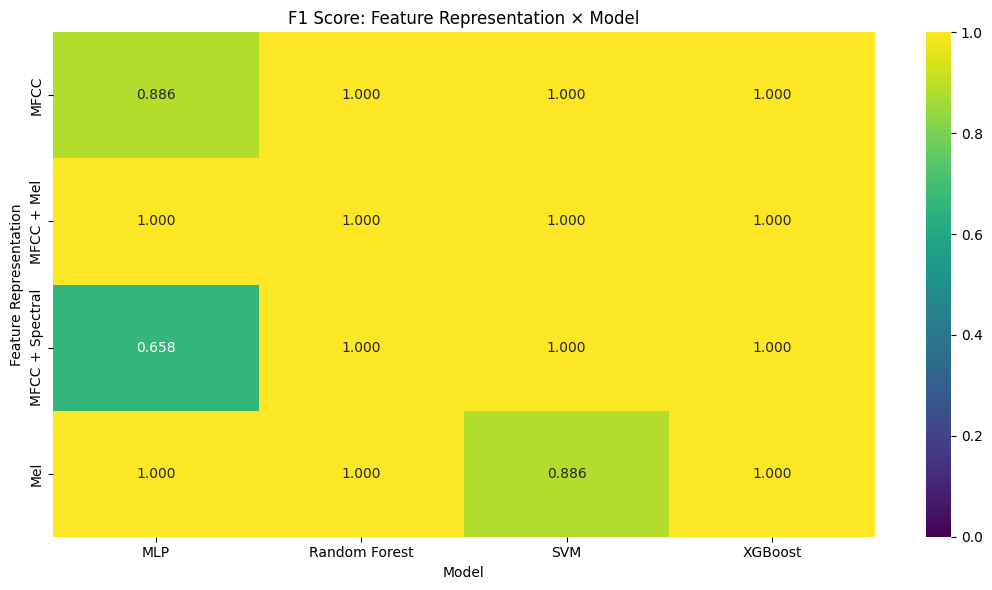

In [ ]:
pivot_f1 = results_df.pivot(
    index="Feature Representation",
    columns="Model",
    values="F1"
)

display(pivot_f1)

plt.figure(figsize=(11, 6))
sns.heatmap(pivot_f1, annot=True, fmt=".3f", cmap="viridis", vmin=0, vmax=1)
plt.title("F1 Score: Feature Representation × Model")
plt.xlabel("Model")
plt.ylabel("Feature Representation")
plt.tight_layout()
plt.show()


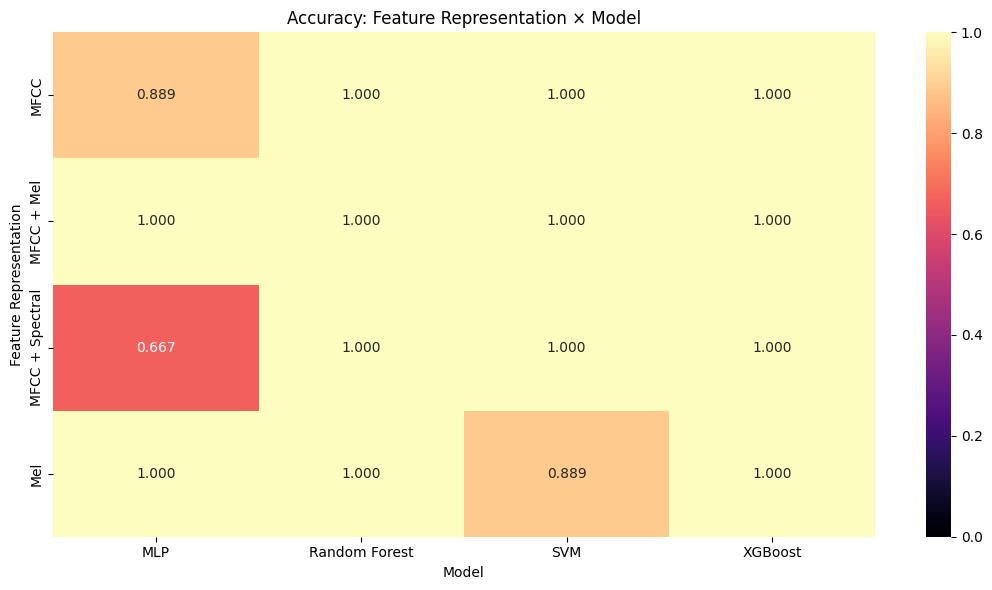

In [ ]:
# Accuracy heatmap
pivot_acc = results_df.pivot(
    index="Feature Representation",
    columns="Model",
    values="Accuracy"
)

plt.figure(figsize=(11, 6))
sns.heatmap(pivot_acc, annot=True, fmt=".3f", cmap="magma", vmin=0, vmax=1)
plt.title("Accuracy: Feature Representation × Model")
plt.xlabel("Model")
plt.ylabel("Feature Representation")
plt.tight_layout()
plt.show()


,Accuracy,Precision,Recall,F1
Feature Representation,,,,
MFCC + Mel,1.000000,1.000000,1.000000,1.000000
MFCC,0.972222,0.976852,0.972222,0.971501
Mel,0.972222,0.976852,0.972222,0.971501
MFCC + Spectral,0.916667,0.916667,0.916667,0.914502


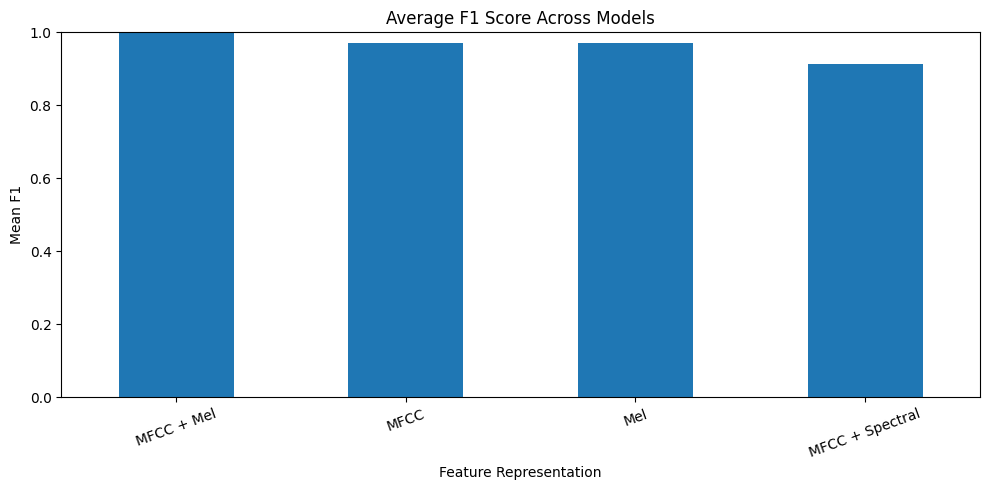

In [ ]:
feature_summary = (
    results_df.groupby("Feature Representation")[["Accuracy", "Precision", "Recall", "F1"]]
    .mean()
    .sort_values("F1", ascending=False)
)

display(feature_summary)

feature_summary["F1"].plot(kind="bar", figsize=(10, 5))
plt.title("Average F1 Score Across Models")
plt.ylabel("Mean F1")
plt.xlabel("Feature Representation")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


,Accuracy,Precision,Recall,F1
Model,,,,
Random Forest,1.000000,1.000000,1.000000,1.000000
XGBoost,1.000000,1.000000,1.000000,1.000000
SVM,0.972222,0.976852,0.972222,0.971501
MLP,0.888889,0.893519,0.888889,0.886003


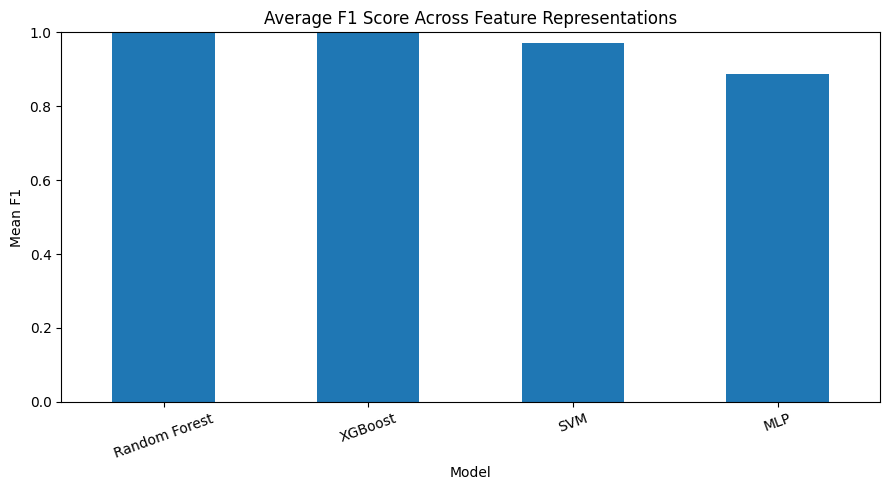

In [ ]:
model_summary = (
    results_df.groupby("Model")[["Accuracy", "Precision", "Recall", "F1"]]
    .mean()
    .sort_values("F1", ascending=False)
)

display(model_summary)

model_summary["F1"].plot(kind="bar", figsize=(9, 5))
plt.title("Average F1 Score Across Feature Representations")
plt.ylabel("Mean F1")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


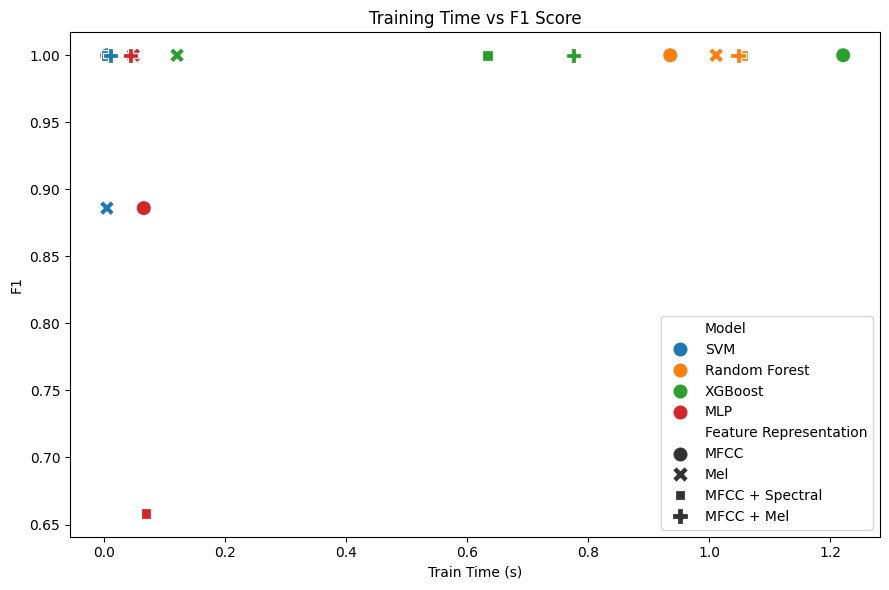

In [ ]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=results_df,
    x="Train Time (s)",
    y="F1",
    hue="Model",
    style="Feature Representation",
    s=120
)
plt.title("Training Time vs F1 Score")
plt.tight_layout()
plt.show()


Best experiment:
Feature Representation        MFCC
Model                          SVM
Accuracy                       1.0
Precision                      1.0
Recall                         1.0
F1                             1.0
ROC-AUC                        1.0
Train Time (s)            0.004379
Inference Time (s)         0.00106
Name: 0, dtype: object

Classification report:
              precision    recall  f1-score   support

        fake     1.0000    1.0000    1.0000         5
        real     1.0000    1.0000    1.0000         4

    accuracy                         1.0000         9
   macro avg     1.0000    1.0000    1.0000         9
weighted avg     1.0000    1.0000    1.0000         9



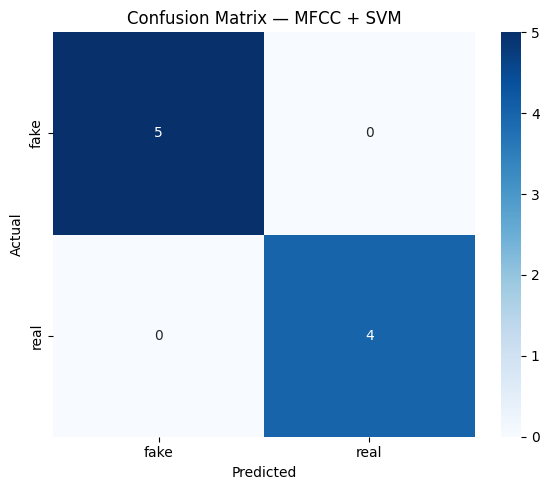

In [ ]:
best_row = results_df.iloc[0]
best_rep = best_row["Feature Representation"]
best_model_name = best_row["Model"]

best_data = feature_sets[best_rep]
best_pred = predictions[(best_rep, best_model_name)]

print("Best experiment:")
print(best_row)

print("\nClassification report:")
print(classification_report(
    best_data["y_test"],
    best_pred,
    digits=4,
    zero_division=0
))

cm = confusion_matrix(best_data["y_test"], best_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=np.unique(best_data["y_test"]),
    yticklabels=np.unique(best_data["y_test"])
)
plt.title(f"Confusion Matrix — {best_rep} + {best_model_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()


In [ ]:
# 5-fold stratified cross-validation.
# This can take a while, especially for MLP and XGBoost.

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_rows = []

for rep in REPRESENTATIONS:
    X = feature_sets[rep]["X_train"]
    y = feature_sets[rep]["y_train"]

    # Encode target labels ('fake', 'real') to integers (0, 1) to prevent XGBoost fit failures
    le = LabelEncoder()
    y_encoded = le.fit_transform(y)

    for model_name, model in models.items():
        scores = cross_validate(
            model,
            X, y_encoded,
            cv=cv,
            scoring=["accuracy", "precision_weighted", "recall_weighted", "f1_weighted"],
            n_jobs=1,
            return_train_score=False
        )

        cv_rows.append({
            "Feature Representation": rep,
            "Model": model_name,
            "CV Accuracy Mean": scores["test_accuracy"].mean(),
            "CV Accuracy Std": scores["test_accuracy"].std(),
            "CV F1 Mean": scores["test_f1_weighted"].mean(),
            "CV F1 Std": scores["test_f1_weighted"].std(),
            "CV Time (s)": scores["fit_time"].sum()
        })

cv_df = pd.DataFrame(cv_rows).sort_values("CV F1 Mean", ascending=False)
display(cv_df)

,Feature Representation,Model,CV Accuracy Mean,CV Accuracy Std,CV F1 Mean,CV F1 Std,CV Time (s)
4,Mel,SVM,0.971429,0.057143,0.971429,0.057143,0.031076
12,MFCC + Mel,SVM,0.971429,0.057143,0.971429,0.057143,0.013174
1,MFCC,Random Forest,0.938095,0.076190,0.937143,0.077512,4.619163
0,MFCC,SVM,0.938095,0.076190,0.937143,0.077512,0.022417
9,MFCC + Spectral,Random Forest,0.938095,0.076190,0.937143,0.077512,3.272796
10,MFCC + Spectral,XGBoost,0.938095,0.076190,0.937143,0.077512,0.194496
8,MFCC + Spectral,SVM,0.938095,0.076190,0.937143,0.077512,0.020525
14,MFCC + Mel,XGBoost,0.938095,0.076190,0.937143,0.077512,1.237801
13,MFCC + Mel,Random Forest,0.938095,0.076190,0.937143,0.077512,3.078324
6,Mel,XGBoost,0.938095,0.076190,0.935873,0.078853,1.092452


In [ ]:
# Difference from the best feature representation for each model.
best_by_model = (
    results_df.loc[
        results_df.groupby("Model")["F1"].idxmax(),
        ["Model", "Feature Representation", "F1"]
    ]
    .rename(columns={"F1": "Best F1"})
)

display(best_by_model)


,Model,Feature Representation,Best F1
7,MLP,Mel,1.0
1,Random Forest,MFCC,1.0
0,SVM,MFCC,1.0
2,XGBoost,MFCC,1.0


In [ ]:
# Example helper for paired comparisons using 5-fold CV.
# Run only after collecting per-fold F1 scores if you want formal significance testing.

from scipy.stats import wilcoxon

def wilcoxon_feature_comparison(scores_a, scores_b):
    stat, p = wilcoxon(scores_a, scores_b)
    return {"statistic": stat, "p_value": p}

print("Use this test on paired fold-level F1 scores for two feature representations.")


Use this test on paired fold-level F1 scores for two feature representations.


,Feature Representation,Dimensions,Mean F1
0,MFCC,26,0.971501
1,Mel,80,0.971501
2,MFCC + Spectral,34,0.914502
3,MFCC + Mel,106,1.000000


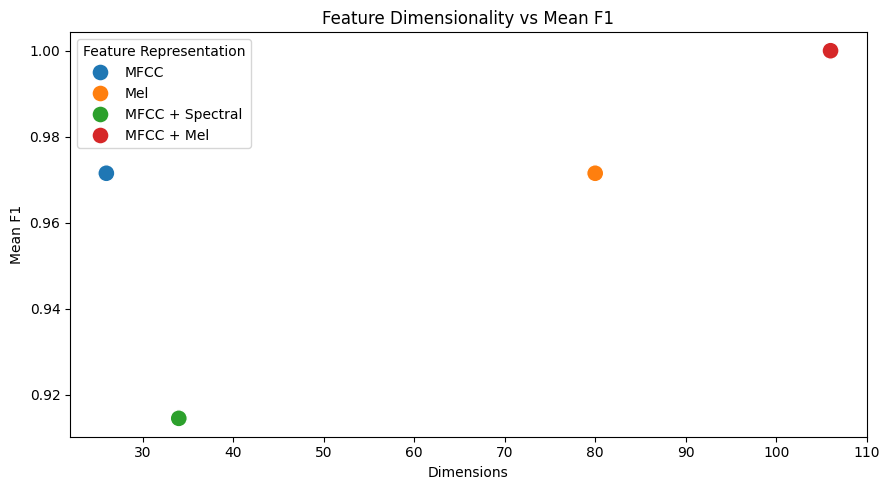

In [ ]:
dim_df = pd.DataFrame({
    "Feature Representation": REPRESENTATIONS,
    "Dimensions": [
        feature_sets[r]["X_train"].shape[1] for r in REPRESENTATIONS
    ],
    "Mean F1": [
        results_df.loc[
            results_df["Feature Representation"] == r, "F1"
        ].mean()
        for r in REPRESENTATIONS
    ]
})

display(dim_df)

plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=dim_df,
    x="Dimensions",
    y="Mean F1",
    hue="Feature Representation",
    s=150
)
plt.title("Feature Dimensionality vs Mean F1")
plt.tight_layout()
plt.show()


In [ ]:
best_overall = results_df.iloc[0]

best_feature = (
    results_df.groupby("Feature Representation")["F1"]
    .mean()
    .idxmax()
)

best_feature_f1 = (
    results_df.groupby("Feature Representation")["F1"]
    .mean()
    .max()
)

best_model = (
    results_df.groupby("Model")["F1"]
    .mean()
    .idxmax()
)

best_model_f1 = (
    results_df.groupby("Model")["F1"]
    .mean()
    .max()
)

print("RESEARCH SUMMARY")
print("=" * 60)
print(f"Best individual experiment: {best_overall['Feature Representation']} + {best_overall['Model']}")
print(f"Best individual F1: {best_overall['F1']:.4f}")
print()
print(f"Best feature representation on average: {best_feature}")
print(f"Mean F1: {best_feature_f1:.4f}")
print()
print(f"Best model on average: {best_model}")
print(f"Mean F1: {best_model_f1:.4f}")
print()
print("Use these values together with the plots and CV variability")
print("to formulate the final research conclusions.")


RESEARCH SUMMARY
Best individual experiment: MFCC + SVM
Best individual F1: 1.0000

Best feature representation on average: MFCC + Mel
Mean F1: 1.0000

Best model on average: Random Forest
Mean F1: 1.0000

Use these values together with the plots and CV variability
to formulate the final research conclusions.


In [ ]:
report_table = results_df.copy()

# Round numerical values for readability.
numeric_cols = report_table.select_dtypes(include=np.number).columns
report_table[numeric_cols] = report_table[numeric_cols].round(4)

display(report_table)

report_table.to_csv("speech_feature_extraction_results.csv", index=False)
cv_df.to_csv("speech_feature_extraction_cv_results.csv", index=False)

print("Saved:")
print("- speech_feature_extraction_results.csv")
print("- speech_feature_extraction_cv_results.csv")


,Feature Representation,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Train Time (s),Inference Time (s)
0,MFCC,SVM,1.0000,1.0000,1.0000,1.000,1.00,0.0044,0.0011
1,MFCC,Random Forest,1.0000,1.0000,1.0000,1.000,1.00,0.9354,0.2226
2,MFCC,XGBoost,1.0000,1.0000,1.0000,1.000,1.00,1.2213,0.0217
5,Mel,Random Forest,1.0000,1.0000,1.0000,1.000,1.00,1.0114,0.0809
7,Mel,MLP,1.0000,1.0000,1.0000,1.000,1.00,0.0478,0.0011
6,Mel,XGBoost,1.0000,1.0000,1.0000,1.000,1.00,0.1200,0.0021
9,MFCC + Spectral,Random Forest,1.0000,1.0000,1.0000,1.000,1.00,1.0554,0.0861
8,MFCC + Spectral,SVM,1.0000,1.0000,1.0000,1.000,1.00,0.0039,0.0034
14,MFCC + Mel,XGBoost,1.0000,1.0000,1.0000,1.000,1.00,0.7748,0.0018
13,MFCC + Mel,Random Forest,1.0000,1.0000,1.0000,1.000,1.00,1.0474,0.0685


Saved:
- speech_feature_extraction_results.csv
- speech_feature_extraction_cv_results.csv
